In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings
import pandas as pd
import pickle
import time
import os
import matplotlib

In [2]:
from cell import cell

beta_vec = [0.0075,0.015,0.03]
max_size=200

def find_tot_plasmids(y1,max_size):
    y1[0]+=y1[1]   #because of plasmid shedding y[1] may have a nonzero value, we transfer this to y[0].
    y1[1]=y1[0]
    y_tot = np.dot(np.arange(1,max_size),y1[1:max_size])
    return y_tot 

def collect_inheritance(cells):
    inheritance = []
    for idx in range(len(cells)):
        focus = cells[idx]
        inheritance = np.append(inheritance,[focus.x[0]])         
    return inheritance

def collect_inherit_poles(cells):
    pole1 = []
    pole2 = []
    for idx in np.arange(1,len(cells)):
        focus = cells[idx].fin_clusters
        pole1.append(find_tot_plasmids(focus[:max_size],max_size))
        pole2.append(find_tot_plasmids(focus[max_size:],max_size))
        
        #pole1 = np.append(pole1,[focus.fin_clusters[0]])   
        #pole2 = np.append(pole2,[cells[idx-1].x[-1]-focus.x[0]])   
    return pole1,pole2

inherit_collect = np.zeros([len(beta_vec),1000])
inherit_pole1 = np.zeros([len(beta_vec),1000-1])
inherit_pole2 = np.zeros([len(beta_vec),1000-1])

k=0
for i in beta_vec:
    filename = './analysis_beta_data/beta'+str(i)+'.pkl'
    with open(filename, 'rb') as file:
        cells = pickle.load(file)
    inherit_collect[k,:] = collect_inheritance(cells)
    inherit_pole1[k,:],inherit_pole2[k,:] = collect_inherit_poles(cells)
    k+=1

C:\Users\Jayson Cortez\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Jayson Cortez\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Jayson Cortez\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


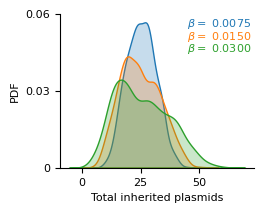

In [3]:
f=plt.figure(figsize=(2.5,2))
ax = f.add_subplot(111)
sns.kdeplot(inherit_collect[0,:],fill=True,ax=ax)
sns.kdeplot(inherit_collect[1,:],fill=True,ax=ax)
sns.kdeplot(inherit_collect[2,:],fill=True,ax=ax)
ax.set_xlabel('Total inherited plasmids',fontsize=8)
ax.set_xticks([0,25,50])
ax.set_xticklabels([0,25,50],fontsize=8)
ax.set_yticks([0,0.03,0.06])
ax.set_yticklabels([0,0.03,0.06],fontsize=8)
ax.text(45,0.055,r'$\beta=$ %1.4f' %(beta_vec[0]),fontsize=8,color='C0')
ax.text(45,0.05,r'$\beta=$ %1.4f' %(beta_vec[1]),fontsize=8,color='C1')
ax.text(45,0.045,r'$\beta=$ %1.4f' %(beta_vec[2]),fontsize=8,color='C2')
ax.set_ylabel('PDF',fontsize=8)
#ax.legend()
sns.despine()


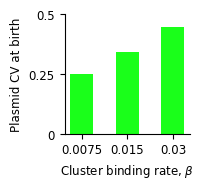

In [5]:
f =plt.figure(figsize=(2.1,2))
ax = f.add_subplot(111)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
col = ["#1AFF1A","#4B0092"]

cv1 = np.std(inherit_collect[0,:])/np.mean(inherit_collect[0,:])
cv2 = np.std(inherit_collect[1,:])/np.mean(inherit_collect[1,:])
cv3 = np.std(inherit_collect[2,:])/np.mean(inherit_collect[2,:])

ax.bar([1,1.5,2],[cv1,cv2,cv3],color=[col[0],col[0],col[0]],width=0.25)
ax.set_ylabel('Plasmid CV at birth',fontsize=fontsiz)
ax.set_xticks([1,1.5,2])
ax.set_xticklabels(beta_vec,fontsize=fontsiz)
ax.set_yticks([0,0.25,0.5])
ax.set_yticklabels([0,0.25,0.5],fontsize=fontsiz)
ax.set_xlabel(r'Cluster binding rate, $\beta$',fontsize=fontsiz)

sns.despine()
plt.tight_layout()
plt.savefig("inheritance_cv.pdf", format="pdf", bbox_inches="tight")

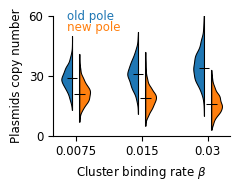

In [4]:
# ---------------- FIGURE ----------------
f = plt.figure(figsize=(2.5, 2))
ax = f.add_subplot(111)

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
fontsiz = 8.5

# ---------------- SETTINGS ----------------
centers = [1.25, 3.25, 5.25]
shift = 0.11          # controls how close the halves are
violin_width = 0.65
box_width = 0.12
box_offset = 0.015    # moves box toward flat face for visual centering


# ---------------- HALF VIOLIN FUNCTION ----------------
def half_violin(data, pos, color, side):
    vp = ax.violinplot(
        data,
        positions=[pos],
        widths=violin_width,
        showmeans=False,
        showmedians=True,
        showextrema=True
    )

    for body in vp['bodies']:
        body.set_facecolor(color)
        body.set_edgecolor('k')
        body.set_linewidth(0.75)
        body.set_alpha(1)

        path = body.get_paths()[0]
        verts = path.vertices
        center = pos

        if side == 'left':
            verts[verts[:, 0] > center, 0] = center
        else:
            verts[verts[:, 0] < center, 0] = center


        # style median line
        vp['cmedians'].set_color('black')
        vp['cmins'].set_visible(False)
        vp['cmaxes'].set_visible(False)
        vp['cbars'].set_color('black')
        vp['cbars'].set_linewidth(0.75)
        vp['cmedians'].set_linewidth(0.75)


# ======================================================
#                       PLOTS
# ======================================================

for i, c in enumerate(centers):

    # positions of halves
    left_pos  = c - shift
    right_pos = c + shift

    # ---- VIOLINS ----
    half_violin(inherit_pole1[i, :], left_pos,  'C0', 'left')
    half_violin(inherit_pole2[i, :], right_pos, 'C1', 'right')


# ---------------- AXES ----------------
ax.set_xticks(centers)
ax.set_xticklabels(beta_vec, fontsize=fontsiz)

ax.set_ylim([0, 60])
ax.set_yticks([0, 30, 60])
ax.set_yticklabels([0, 30, 60], fontsize=fontsiz)

ax.set_xlabel(r'Cluster binding rate $\beta$', fontsize=fontsiz)
ax.set_ylabel('Plasmids copy number', fontsize=fontsiz)

ax.text(1, 58, 'old pole', color='C0', fontsize=fontsiz)
ax.text(1, 52.5, 'new pole', color='C1', fontsize=fontsiz)

sns.despine()
plt.tight_layout(h_pad=1)

plt.savefig("pole_segregation.pdf", format="pdf", bbox_inches="tight")

In [ ]:
old_clust = inherit_pole1[1,:]
new_clust = inherit_pole2[1,:]
np.savetxt("old_cluston.csv", old_clust, delimiter=",",header=" ")
np.savetxt("new_cluston.csv", new_clust, delimiter=",",header=" ")

# Analyze Free Plasmids

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings
import pandas as pd
import pickle
import time
import os
import matplotlib

In [9]:
#single cell dynamics
##################################################
class cell:
    def __init__(self,index,init_clusters,parent,birth,tau):
        '''Initializes cell attributes
        param:: index: cell index
        param:: clusters: count of n-clusters
        param:: x: plasmid trajectory in time 
        param:: t: time stamps for x
        param:: parent: parent cell
        param:: birth: birth time
        return:: None
        '''
        self.index=index
        self.init_clusters=init_clusters
        self.fin_clusters=[]
        self.x = []
        self.t = []
        self.parent = parent
        self.birth = birth
        self.div = birth+tau+np.random.normal(0,1)

def find_tot_plasmids(y1,y2,max_size):
    y1[0]+=y1[1]   #because of plasmid shedding y[1] may have a nonzero value, we transfer this to y[0].
    y2[0]+=y2[1]
    y1[1]=y1[0]
    y2[1]=y2[0]
    y_tot1 = np.dot(np.arange(1,max_size),y1[1:max_size])
    y_tot2 = np.dot(np.arange(1,max_size),y2[1:max_size])            
    y_tot = y_tot1+y_tot2
    y1[1]=0
    y2[1]=0
    return y1,y2,y_tot1,y_tot2,y_tot 

def pop_check(cells,T):
    b_filter = [x for x in cells if x.t[0] <= T]
    d_filter = [x for x in b_filter if x.t[-1] >T]
    return d_filter #N_pop

def hazards(y,c_idx,num_reax,N,beta,gamma,sigma,max_size,t_f,y_totp,y_tot): 
    a = np.zeros(num_reax)                                     #reaction hazards 
    v = np.zeros([num_reax,max_size])                           #reaction vectors    
    #V = V0*np.exp(mu*t_f)
    a[0]= 1 #(k_tr*y_totp)/(1+K*y_tot/(s0*6.022e2*n*V))**n    #not needed since computation of reaction time is different 
    v[0,0] = 1
    a[1] = 0.5*beta*y[0]*(y[0]-1)
    v[1,0] = -2
    v[1,2] = 1
    
    if N>1:
        species_idx =np.zeros([2,num_reax])
        count=1
        for i in np.arange(1,N):   #plasmid recruitment
            count+=1
            a[count] = beta*y[0]*y[c_idx[i]]
            species_idx[:,count] = np.array([c_idx[i],0])
        rec_count=count
                
        for i in np.arange(1,N):   #cluster combination
            for j in np.arange(i,N):
                count+=1
                if i==j:
                    a[count] = 0.5*gamma*y[c_idx[i]]*(y[c_idx[j]]-1)
                else:
                    a[count] = gamma*y[c_idx[i]]*y[c_idx[j]]
                species_idx[:,count] = [c_idx[i],c_idx[j]]
        cluster_count = count
            
        for i in np.arange(1,N): #plasmid shedding
            count+=1
            a[count] = sigma*y[c_idx[i]]*c_idx[i]
            species_idx[:,count] = np.array([c_idx[i],0])
                    
        for i in range(len(a)): #reaction vectors
            if i==0:                         #plasmid replication
                v[i,0] = 1
            elif i==1:                       #plasmid duplex formation
                v[i,0] = -2
                v[i,2] = 1
            elif (2<=i and i<=rec_count):    #plasmid recruitment to a cluster
                v[i,0] = -1
                v[i,int(species_idx[0,i])] = -1
                v[i,int(species_idx[0,i])+1] = 1
            elif (i>rec_count and i<=cluster_count):   #cluster combination
                if (int(species_idx[0,i])==int(species_idx[1,i]) and y[int(species_idx[1,i])]>1 ):
                    v[i,int(species_idx[0,i])] = -2
                    v[i,int(np.sum(species_idx[:,i]))] = 1
                elif not(int(species_idx[0,i])==int(species_idx[1,i])):
                    v[i,int(species_idx[0,i])] = -1
                    v[i,int(species_idx[1,i])] = -1
                    v[i,int(np.sum(species_idx[:,i]))] = 1
            else:  #plasmid shedding         
                if int(species_idx[0,i]) == 2:   
                    v[i,0] = 2
                    v[i,int(species_idx[0,i])] = -1 
                else:
                    v[i,0] = 1
                    v[i,int(species_idx[0,i])] = -1
                    v[i,int(species_idx[0,i])-1] = 1 
    return a,v

def time_approx(s,xi,y_tot,eps):
    D=k_tr*xi
    V=V0*np.exp(mu*s)
    C=K*y_tot/(s0*6.022e2*n)
    a_prime = (mu*n*D*C/V)*(1+C/V)**(-n-1)
    a = D/(1+C/V)**n 
    return (-a+np.sqrt(a**2-2*a_prime*np.log(eps)))/a_prime

def ssa_vol(y0,x0,tau,beta,gamma,sigma,max_size):
    y=y0               #plasmid cluster count; y[0]=x[0], y[1]=0, y[i] = number of cluster of size i     
    x=[x0]
    t_x = [0]
    t_y=0             #reaction time 
    y_tot1=x0
    y_tot2 = 0
    clust = [y]
    ty = []
    y1 = y[:max_size]
    y2 = y[max_size:2*max_size] 
    y_tot=y_tot1+y_tot2
    while t_y<tau:
        #print('########## new reaction')
        ############################### pole 1 ##################################    
        if y_tot1>0:
            dummy = y1[0]                                               
            y1[0] = 1
            c_idx1 = np.where(y1>0)[0]                                  #indices of species with non-zero state except possibly free plasmids
            y1[0] = dummy
            N1 = len(c_idx1)                                            #number of non-zero species
            num_reax1 = N1+1+int(((N1-1)**2-N1+1)/2)+2*(N1-1)           #possible number of reactions given the system state 
            a1,v1 = hazards(y1,c_idx1,num_reax1,N1,beta,gamma,sigma,max_size,t_y,y_tot1,y_tot)     
        else:
            num_reax1 = 1
            a1 = [0]
            v1 = np.zeros([1,max_size])
        
        ############################### pole 2 ##################################
        if y_tot2>0:
            dummy = y2[0]
            y2[0]=1
            c_idx2 = np.where(y2>0)[0]                                  
            y2[0]=dummy
            N2 = len(c_idx2)
            num_reax2 = N2+1+int(((N2-1)**2-N2+1)/2)+2*(N2-1)  
            a2,v2 = hazards(y2,c_idx2,num_reax2,N2,beta,gamma,sigma,max_size,t_y,y_tot2,y_tot)
            a = np.append(a1,a2,axis=0)
       
        else:
            num_reax2 = 1
            a2 = [0]
            a = np.append(a1,a2,axis=0)
            v2 = np.zeros([1,max_size])
            
        a = np.append(a,[rho*y1[0],rho*y2[0]])
        epsilon=np.random.uniform(0,1,len(a))
        t_j  = np.zeros(num_reax1+num_reax2+2)
        
        for i in range(len(a)):
            if a[i]==0:
                t_j[i] = np.inf
            else:
                if i == 0: #replication in pole 1
                    t_j[i] = time_approx(t_y,y_tot1,y_tot,epsilon[i])
                elif i == num_reax1:  #replication in pole 2
                    t_j[i] = time_approx(t_y,y_tot2,y_tot,epsilon[i])
                else:
                    t_j[i] = -np.log(epsilon[i])/a[i]
        j=np.argmin(t_j)
        
        if (j==num_reax1+num_reax2): #plasmid transfer pole 1 to 2
            y2[0]+=1
            y1[0]-=1
        elif (j==num_reax1+num_reax2+1): #plasmid transfer pole 2 to 1
            y2[0]-=1
            y1[0]+=1
        elif (num_reax1<=j and j<num_reax1+num_reax2):
            y2+=v2[j-num_reax1,:]  
        else:
            y1+=v1[j,:]    
        y1,y2,y_tot1,y_tot2,y_tot = find_tot_plasmids(y1,y2,max_size)
        if (j==0 or j==num_reax1):
            x= np.append(x,y_tot)
            t_x =np.append(t_x,[t_y])
        t_y+=t_j[j]
        ty =np.append(ty,[t_y]) 
        clust = np.vstack((clust,np.append(y1,y2,axis=0)))

    y = np.append(y1,y2,axis=0)
    return y,x,t_x,clust,ty

def sim_cells(current,beta,gamma,sigma,max_size):
    y0 = current.init_clusters
    y0[1]=y0[0]
    x0 = np.dot(np.arange(1,max_size),y0[1:max_size])
    y0[1]=0 
    if x0>0:
        yy,xx,tt,clust,ty = ssa_vol(y0,x0,current.div-current.birth,beta,gamma,sigma,max_size)
    else:
        yy = y0
        xx = np.array([0,0])
        tt = np.array([0,current.div-current.birth])
        clust = np.zeros(max_size)
        ty = np.array([0,current.div-current.birth])
    return yy,xx,tt,clust,ty

def lineage_sim(c,tau,beta,gamma,sigma,max_size,leng):
    Line=[]
    current_cell = c 
    N=0
    length = 1
    status =1
    free1 = []
    free2 = []
    while status == 1:
        #print('############## new cell ##############')
        zz0 = np.copy(current_cell.init_clusters) 
        yy,xx,tt,clust,ty= sim_cells(current_cell,beta,gamma,sigma,max_size)
        current_cell.fin_clusters = yy
        current_cell.x = xx
        current_cell.t = tt+current_cell.birth  
        current_cell.init_clusters = zz0
        free1=np.append(free1,[np.mean(clust[:,0])])
        free2=np.append(free2,[np.mean(clust[:,max_size])])
        Line.extend([current_cell])
        if len(Line)>10:
            Line.remove(Line[0]) 
        
        if np.random.uniform(0,1)<0.5:
            daughter = cell(N+1,np.append(yy[:max_size],np.zeros(max_size)),current_cell.index,current_cell.t[-1],tau)
        else:
            daughter = cell(N+1,np.append(yy[max_size:],np.zeros(max_size)),current_cell.index,current_cell.t[-1],tau)
        x0 = np.dot(np.arange(1,max_size),daughter.init_clusters[1:max_size])+daughter.init_clusters[0]
        
        if current_cell.x[-1]==x0 or x0==0 or length==leng:
            status = 0
        else:
            length+=1
            status = 1
            current_cell = daughter
            N+=1
        ty=np.append([0],ty)
    return Line,length,clust,ty,free1,free2

##################################################
n =  2.56  #4.84 #2.56 #8.85
s0 = 0.034 #0.06 #0.034 #0.08  
tau = 30             #30-min doubling time
k_tr = 2.17       
K = 15.8/1.26  
mu = np.log(2)/tau
V0 = 1.2
rho = 0.13

x0=25          #number of plasmids in the initial cell
max_size=200   #total number of possible clusters, can be increased to accomodate larger sims

true_beta = 0.015
true_sigma = 0.08
true_gamm = 0.05

##################################################

warnings.filterwarnings('ignore')
beta_vec = [0.0075,0.015,0.03]
repeats = len(beta_vec)
loss = np.zeros(repeats)
length=1000
free_plasmids1 = np.zeros([length,repeats])
free_plasmids2 = np.zeros([length,repeats])
for k in range(repeats):
    y0 = np.zeros(2*max_size)
    y0[0]=x0
    c= cell(0,y0,[],0,tau)   #index,clusters,parent,birth
    Line,length,clust,ty,free1,free2 = lineage_sim(c,tau,beta_vec[k],true_gamm,true_sigma,max_size,length)
    loss[k] = 1./length
    free_plasmids1[:,k] = free1
    free_plasmids2[:,k] = free2
print('Loss prob',np.mean(loss))


Loss prob 0.001


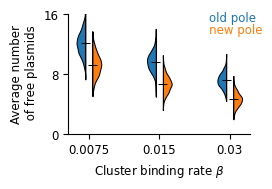

In [10]:
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns  # for despine

# ---------------------------
# FIGURE SETUP
# ---------------------------
f, ax = plt.subplots(figsize=(2.75,2))
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
fontsiz = 8.5

col = ["#1AFF1A","#4B0092"]  # colors
tags = [0.0075,0.015,0.03]   # x-axis labels
positions = [1,3,5]           # positions of categories
violin_width = 0.5           # width of each violin

# ---------------------------
# HALF VIOLIN FUNCTION
# ---------------------------
def half_violin(data, pos, color, side):
    if len(data) == 0:
        return

    vp = ax.violinplot(
        data,
        positions=[pos],
        widths=violin_width,
        showmeans=False,
        showmedians=True,
        showextrema=True
    )

    for body in vp['bodies']:
        body.set_facecolor(color)
        body.set_edgecolor('k')
        body.set_linewidth(0.75)
        body.set_alpha(1)

        # clip half to left or right
        path = body.get_paths()[0]
        verts = path.vertices
        center = pos
        if side == 'left':
            verts[verts[:,0] > center, 0] = center
        else:
            verts[verts[:,0] < center, 0] = center

    # style median / vertical line
    vp['cmedians'].set_color('black')
    vp['cmedians'].set_linewidth(0.75)
    vp['cmins'].set_visible(False)
    vp['cmaxes'].set_visible(False)
    vp['cbars'].set_color('black')
    vp['cbars'].set_linewidth(0.75)

# ---------------------------
# DRAW HALF VIOLINS
# ---------------------------
shift = violin_width / 5  # small offset to avoid overlap

for i, pos in enumerate(positions):
    # old pole = left
    half_violin(free_plasmids1[:,i], pos - shift, 'C0', side='left')
    # new pole = right
    half_violin(free_plasmids2[:,i], pos + shift, 'C1', side='right')

# ---------------------------
# AXES SETTINGS
# ---------------------------
ax.set_xticks(positions)
ax.set_xticklabels(tags, fontsize=fontsiz)
ax.set_yticks([0,8,16])
ax.set_ylim([0,16])
ax.tick_params(axis='y', labelsize=fontsiz)
ax.tick_params(axis='x', labelsize=fontsiz)

ax.set_xlabel(r'Cluster binding rate $\beta$', fontsize=fontsiz)
ax.set_ylabel('Average number\n of free plasmids', fontsize=fontsiz)

# ---------------------------
# TEXT LABELS / LEGEND
# ---------------------------
ax.text(4.4,15,'old pole', color='C0', fontsize=fontsiz)
ax.text(4.4,13.5,'new pole', color='C1', fontsize=fontsiz)

sns.despine()
plt.tight_layout()
plt.savefig("free_plasmids.pdf", format="pdf", bbox_inches="tight")
plt.show()

# Loss Probability

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings
import pandas as pd
import pickle
import time
import os
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.ticker import StrMethodFormatter, NullFormatter

$\beta$= 0.0075 mean= 2.6187137519681145e-08 std= 2.4526501122915547e-09
a= 114 b= 4353282100.0
$\beta$= 0.015 mean= 6.101933788449739e-07 std= 5.5936318118970384e-08
a= 119 b= 195020024.0
$\beta$= 0.03 mean= 1.6780941917603798e-05 std= 1.3656021519143788e-06
a= 151 b= 8998152.0


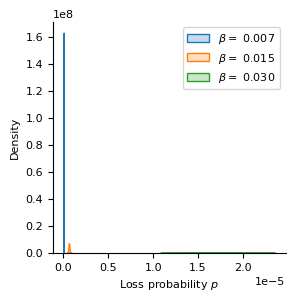

In [12]:
alpha = 1  #prior beta distribution parameter
beta = 1   #prior beta distribution parameter
beta_vec = [0.0075,0.015,0.03]

fig = plt.figure(figsize=(3,3))
plt.rc('font', size=8)
ax = fig.add_subplot(111)
means_p = np.zeros(len(beta_vec))
std_p = np.zeros(len(beta_vec))
kk=0
a_vec=np.zeros(len(beta_vec))
b_vec=np.zeros(len(beta_vec))
for be in beta_vec:
    filename = './analysis_beta_data/beta'+str(be)+'.csv'
    loss = pd.read_csv(filename).values
    obs = 1./loss
    n = len(obs)
    sum_obs = np.sum(obs)-n 
    a = alpha+n
    b= beta+sum_obs
    a_vec[kk] = a
    b_vec[kk] = b
    
    mean=a/(a+b)
    std=np.sqrt(a*b/((a+b+1)*(a+b)**2))
    means_p[kk] =mean
    std_p[kk] =std
    samp = np.random.beta(a,b,100000)
    print(r'$\beta$=',be,'mean=',mean,'std=',std)
    print('a=',a,'b=',b)
    sns.kdeplot(samp,ax=ax,fill='True',label=r'$\beta=$ %0.3f' %(be))
    ax.set_xlabel(r'Loss probability $p$')
    sns.despine()
    kk+=1
plt.legend()

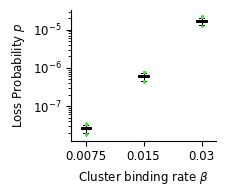

In [13]:
import matplotlib

def box_plot(data, edge_color, fill_color,pos,out_color):
    bp = ax.boxplot(data, patch_artist=True,positions=pos,showfliers=True,widths=0.35,sym=out_color)
    for element in ['boxes', 'whiskers', 'fliers', 'means', 'medians', 'caps']:
        plt.setp(bp[element], color=edge_color, linewidth=0.75)
    for patch in bp['boxes']:
        patch.set(facecolor=fill_color)       
    plt.setp(bp['fliers'], color=edge_color, linewidth=0.25,markersize=1)
    return bp


f= plt.figure(figsize=(2.3,2))
ax = f.add_subplot(111)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
col = ["#1AFF1A","#4B0092"]

tags = [0.0075,0.015,0.03]
fontsiz = 8.5

#impeded segregation
clust_model1 = box_plot(np.random.beta(a_vec[0],b_vec[0],1000), 'k', col[0],[1], col[0])
clust_model2 = box_plot(np.random.beta(a_vec[1],b_vec[1],1000),'k', col[0],[3], col[0])
clust_model3 = box_plot(np.random.beta(a_vec[2],b_vec[2],1000), 'k', col[0],[5], col[0])

ax.set_yscale("log")
ax.tick_params(axis='y')
ax.set_xticks([1,3,5])
ax.set_xticklabels(tags,fontsize=fontsiz)
ax.tick_params(axis='both', which='major', labelsize=fontsiz)
ax.set_xlabel(r'Cluster binding rate $\beta$',fontsize=fontsiz)
ax.set_ylabel(r'Loss Probability $p$',fontsize=fontsiz)
sns.despine()
plt.tight_layout()
plt.savefig("loss_prob_beta.pdf", format="pdf", bbox_inches="tight")

# Plasmid Shedding

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings
import pandas as pd
import pickle
import time
import os
import matplotlib
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

$\epsilon$= 0.04 mean= 8.90124609782045e-06 std= 7.243698890395552e-07
a= 151 b= 16963766.0
$\epsilon$= 0.08 mean= 6.101933788449739e-07 std= 5.5936318118970384e-08
a= 119 b= 195020024.0
$\epsilon$= 0.12 mean= 3.8737899714866104e-07 std= 5.2715594049639654e-08
a= 54 b= 139398314.0


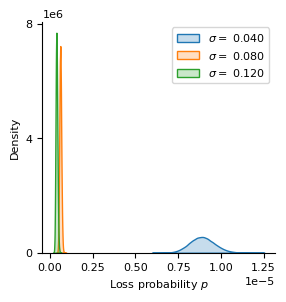

In [15]:
alpha = 1
beta = 1
sigma_vec = [0.04,0.08,0.12]

fig = plt.figure(figsize=(3,3))
plt.rc('font', size=8)
ax = fig.add_subplot(111)
means_p = np.zeros(3)
std_p = np.zeros(3)
kk=0

a_vec=np.zeros(3)
b_vec=np.zeros(3)
for sigma in sigma_vec:
    filename = './analysis_beta_data/sigma'+str(sigma)+'.csv'
    loss = pd.read_csv(filename).values
    obs = 1./loss
    n = len(obs)
    sum_obs = np.sum(obs)-n 
    a = alpha+n
    b= beta+sum_obs
    a_vec[kk] = a
    b_vec[kk] = b
    
    mean=a/(a+b)
    std=np.sqrt(a*b/((a+b+1)*(a+b)**2))
    means_p[kk] =mean
    std_p[kk] =std
    samp = np.random.beta(a,b,100000)
    print('$\epsilon$=',sigma,'mean=',mean,'std=',std)
    print('a=',a,'b=',b)
    sns.kdeplot(samp,ax=ax,fill='True',label=r'$\sigma=$ %0.3f' %(sigma))
    ax.set_xlabel(r'Loss probability $p$')
    ax.set_yticks([0,4e6,8e6])
    sns.despine()
    kk+=1
plt.legend()

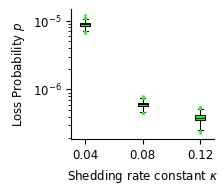

In [16]:
def box_plot(data, edge_color, fill_color,pos,out_color):
    bp = ax.boxplot(data, patch_artist=True,positions=pos,showfliers=True,widths=0.35,sym=out_color)
    for element in ['boxes', 'whiskers', 'fliers', 'means', 'medians', 'caps']:
        plt.setp(bp[element], color=edge_color, linewidth=0.75)
    for patch in bp['boxes']:
        patch.set(facecolor=fill_color)       
    plt.setp(bp['fliers'], color=edge_color, linewidth=0.25,markersize=1)
    return bp

def box_plot_ins(data, edge_color, fill_color,pos,out_color):
    bp = ins_ax.boxplot(data, patch_artist=True,positions=pos,showfliers=True,widths=0.35,sym=out_color)
    for element in ['boxes', 'whiskers', 'fliers', 'means', 'medians', 'caps']:
        plt.setp(bp[element], color=edge_color, linewidth=0.75)
    for patch in bp['boxes']:
        patch.set(facecolor=fill_color)       
    plt.setp(bp['fliers'], color=edge_color, linewidth=0.25,markersize=1)
    return bp


fig = plt.figure(figsize=(2.3,2))
plt.rc('font', size=8.5)
fontsiz=8.5
ax = fig.add_subplot(111)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
tags = [0.04, 0.08, 0.12]
col = ["#1AFF1A","#4B0092"]

#impeded segregation
clust_model1 = box_plot(np.random.beta(a_vec[0],b_vec[0],1000), 'k', col[0],[1], col[0])
clust_model2 = box_plot(np.random.beta(a_vec[1],b_vec[1],1000),'k', col[0],[3], col[0])
clust_model3 = box_plot(np.random.beta(a_vec[2],b_vec[2],1000), 'k', col[0],[5], col[0])

ax.set_yscale("log")
ax.tick_params(axis='y')
ax.set_xticks([1,3,5])
ax.set_xticklabels(tags)
ax.set_xlabel(r'Shedding rate constant $\kappa$',fontsize=fontsiz)
ax.set_ylabel(r'Loss Probability $p$',fontsize=fontsiz)
sns.despine()
plt.tight_layout()
plt.savefig("shedding.pdf", format="pdf", bbox_inches="tight")